# Exploratory data analysis – Save the Pandas
**Input:** `data/cleaned_data.csv` (from `scripts/preprocess.py`): one row per NOAA significant earthquake with a magnitude, 1960–2024, joined with World Bank GDP per capita (constant 2015 US$) and US CPI.

**Research questions**
1. How is a country's level of economic prosperity associated with earthquake-related loss of lives and economic damage?
2. How do human and economic losses differ between significant earthquakes with and without a recorded tsunami association within the same half-unit magnitude band?
3. Are earthquakes with higher reported loss of lives also associated with greater economic damage?

Structure follows the guidelines: first contact → one variable at a time → relationships (one part per research question). Every section ends with a **Findings** cell.

*A blank death or damage value means that NOAA gives no number: the event may have had no losses or the losses are unknown (the data do not separate the two). Reported losses are estimates.*

*NOAA lists an earthquake if it meets at least one criterion: moderate damage (about $1 million or more), 10 or more deaths, magnitude 7.5 or greater, Modified Mercalli intensity X or greater, or a tsunami ([NOAA NCEI](https://www.ncei.noaa.gov/products/natural-hazards/tsunamis-earthquakes-volcanoes/earthquakes)). The database is therefore a selection of significant events, not all earthquakes.*

*All confidence intervals are bootstrap intervals. Unless stated otherwise they resample individual earthquakes, which treats events as independent; they are exploratory. RQ1 also reports a country-cluster bootstrap.*

In [4]:
import os
os.chdir("/content")
if not os.path.exists("ie421-2026-2027-1-termproject-save-the-pandas"):
    !git clone https://github.com/BILGI-IE-421/ie421-2026-2027-1-termproject-save-the-pandas.git
%cd /content/ie421-2026-2027-1-termproject-save-the-pandas/scripts

/content/ie421-2026-2027-1-termproject-save-the-pandas/scripts


In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root: works when the notebook is run from scripts/ or from the root
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))

# Shared code lives in scripts/figures.py, so the notebook and the figures on the site
# use exactly the same data preparation, groups and bootstrap intervals.
from figures import (BLUE, ORANGE, MAG_ORDER, GDP_LABELS, load_data, add_groups,
                     median_ci, spearman_ci, median_diff_ci, spearman_cluster_ci,
                     fig1_rq1, fig2_rq2)

# Adds mag_band (half-unit magnitude bands, RQ2), decade and gdp_quartile (income quarters, RQ1)
df = add_groups(load_data())
pd.set_option("display.max_columns", 40)


## 1. First contact
### 1.1 Size, column types and a random sample

In [6]:
print(df.shape)
df.dtypes.to_frame("dtype")

(2635, 19)


,dtype
id,int64
year,int64
date,datetime64[ns]
country,object
ISO3,object
eqMagnitude,float64
tsunami,int64
deathsTotal,float64
death_description,float64
Death_Status,object


In [7]:
df.sample(8, random_state=421)

,id,year,date,country,ISO3,eqMagnitude,tsunami,deathsTotal,death_description,Death_Status,damageMillionsDollarsTotal,damage_description,Economic_Damage_Status,Total_Damage_2024_USD_Millions,GDP_per_capita_2015USD,gdp_missing_reason,CPI_annual,mag_band,decade
2056,10124,2015,2015-02-26,PAKISTAN,PAK,5.4,0,NaN,NaN,Unknown,NaN,1.0,Damage Reported,NaN,1380.470208,GDP available,237.017000,<6.0,2010
949,5508,1998,1998-11-13,IRAN,IRN,5.4,0,5.0,1.0,Deaths Reported,NaN,NaN,Unknown,NaN,3704.565630,GDP available,163.008333,<6.0,1990
981,5545,1999,1999-11-26,VANUATU,VUT,7.5,1,10.0,1.0,Deaths Reported,NaN,3.0,Damage Reported,NaN,3088.798164,GDP available,166.575000,7.5-7.9,1990
630,5137,1987,1987-08-02,CHINA,CHN,4.9,0,NaN,NaN,Unknown,NaN,3.0,Damage Reported,NaN,797.416224,GDP available,113.625000,<6.0,1980
2032,10098,2014,2014-05-19,ALBANIA,ALB,5.0,0,NaN,NaN,Unknown,NaN,1.0,Damage Reported,NaN,4045.119349,GDP available,236.736167,<6.0,2010
819,5355,1993,1993-06-22,IRAN,IRN,5.4,0,24.0,1.0,Deaths Reported,NaN,NaN,Unknown,NaN,3514.519666,GDP available,144.458333,<6.0,1990
2343,10446,2019,2019-09-21,ALBANIA,ALB,5.6,0,NaN,NaN,Unknown,45.0,4.0,Damage Reported,55.214504,5072.436484,GDP available,255.657417,<6.0,2010
1669,8134,2008,2008-09-11,JAPAN,JPN,6.8,1,NaN,NaN,Unknown,NaN,NaN,Unknown,NaN,34008.591515,GDP available,215.302500,6.5-6.9,2000


### 1.2 Identifiers and duplicates

In [8]:
print("id is unique:", df["id"].is_unique)
print("Exact duplicate rows:", df.duplicated().sum())
print("Same date, country and magnitude (possible duplicates to inspect):",
      df.duplicated(subset=["date", "country", "eqMagnitude"]).sum())

id is unique: True
Exact duplicate rows: 0
Same date, country and magnitude (possible duplicates to inspect): 2


In [9]:
# Show the possible duplicates: two events on the same day in the same country with the same magnitude
df.loc[df.duplicated(subset=["date", "country", "eqMagnitude"], keep=False),
       ["id", "date", "country", "eqMagnitude", "tsunami", "deathsTotal"]]

,id,date,country,eqMagnitude,tsunami,deathsTotal
1782,8953,2002-08-19,FIJI,7.7,0,NaN
1783,8954,2002-08-19,FIJI,7.7,0,NaN
2090,10165,2015-11-24,PERU,7.6,0,NaN
2091,10166,2015-11-24,PERU,7.6,0,NaN


### 1.3 Missing values

In [10]:
miss = df.isna().agg(["sum", "mean"]).T.rename(columns={"sum": "missing", "mean": "share"})
miss["share"] = miss["share"].round(3)
miss.sort_values("share", ascending=False)

,missing,share
damageMillionsDollarsTotal,2074.0,0.787
Total_Damage_2024_USD_Millions,2074.0,0.787
deathsTotal,1489.0,0.565
death_description,1470.0,0.558
damage_description,599.0,0.227
GDP_per_capita_2015USD,257.0,0.098
ISO3,93.0,0.035
date,0.0,0.000
year,0.0,0.000
id,0.0,0.000


In [11]:
# How much do we know about losses? ("Unknown" = blank in NOAA)
pd.concat([df["Death_Status"].value_counts(), df["Economic_Damage_Status"].value_counts()],
          axis=1, keys=["deaths", "damage"]).fillna(0).astype(int)

,deaths,damage
Unknown,1469,599
Deaths Reported,1166,0
Damage Reported,0,2036


In [12]:
# Can we tell a true zero from an unknown? Count explicit zeros in numbers and description codes.
print("deathsTotal == 0:", (df["deathsTotal"] == 0).sum())
print("death_description == 0 (None):", (df["death_description"] == 0).sum())
print("damage_description == 0 (None):", (df["damage_description"] == 0).sum())
print("\ndeath_description codes:", df["death_description"].value_counts(dropna=False).sort_index().to_dict())
print("damage_description codes:", df["damage_description"].value_counts(dropna=False).sort_index().to_dict())

deathsTotal == 0: 0
death_description == 0 (None): 0
damage_description == 0 (None): 0

death_description codes: {1.0: 917, 2.0: 64, 3.0: 116, 4.0: 68, nan: 1470}
damage_description codes: {1.0: 722, 2.0: 667, 3.0: 301, 4.0: 346, nan: 599}


In [13]:
# Why is GDP missing? (country not matched vs no World Bank value)
print(df["gdp_missing_reason"].value_counts().to_string(), "\n")

# NOAA country names that could not be matched to a World Bank country
df.loc[df["gdp_missing_reason"] == "No ISO3 match", "country"].value_counts()

gdp_missing_reason
GDP available                      2378
No World Bank GDP for this year     164
No ISO3 match                        93 



,count
country,
TAIWAN,47
USA TERRITORY,16
CONGO,6
SOUTH GEORGIA AND THE SOUTH SANDWICH ISLANDS,6
ANTARCTICA,5
GUADELOUPE,4
ATLANTIC OCEAN,3
UK TERRITORY,1
WALLIS AND FUTUNA (FRENCH TERRITORY),1


**Findings (first contact)**
- The dataset contains 2,635 earthquakes (1960–2024, all with a magnitude), 17 original variables and 3 variables derived by `add_groups()` in `scripts/figures.py` (`mag_band`, `decade`, `gdp_quartile`). `id` is a unique identifier; there are no exact duplicate rows.
- Two pairs share date, country and magnitude (Fiji, 19 Aug 2002, M7.7; Peru, 24 Nov 2015, M7.6). Two pairs of records share the same date, country and magnitude but have different NOAA event IDs. They are retained as separate catalog records. However, their physical distinction could not be independently verified using the available data. We keep both; the time of day is not in our cleaned file, so we cannot check this further here.
- Losses are often missing: numeric damage is missing for 79% of events and the death toll for 57%. GDP is missing for 10% (164 events have no World Bank value for that year; 93 could not be matched to a World Bank country, 47 of them Taiwan).
- **The data cannot separate "no deaths" from "unknown":** there is no explicit 0 in `deathsTotal` or in the description codes. NOAA leaves the field blank in both cases, so `Unknown` means "zero or not reported".
- For damage, a verbal code exists far more often than a number: 77% of events have a damage description, but only 21% have a dollar figure.

## 2. One variable at a time
### 2.1 Summary statistics

In [14]:
num = ["eqMagnitude", "deathsTotal", "damageMillionsDollarsTotal",
       "Total_Damage_2024_USD_Millions", "GDP_per_capita_2015USD"]
df[num].describe(percentiles=[.25, .5, .75, .9, .99]).T.round(2)

,count,mean,std,min,25%,50%,75%,90%,99%,max
eqMagnitude,2635.0,6.11,1.03,1.60,5.40,6.10,6.90,7.50,8.20,9.50
deathsTotal,1146.0,1364.86,14386.06,1.00,2.00,5.00,30.00,300.00,20002.75,316000.00
damageMillionsDollarsTotal,561.0,1738.84,11421.81,0.01,5.00,43.00,285.00,2000.00,28800.00,220136.60
Total_Damage_2024_USD_Millions,561.0,3086.29,17819.46,0.10,14.31,78.42,557.71,4292.86,45099.66,306991.42
GDP_per_capita_2015USD,2378.0,10175.93,13229.69,145.46,2084.25,4277.88,11375.15,33157.35,55665.24,80448.97


Deaths and damage are extremely right-skewed (mean far above median), so we use medians and log scales below.

### 2.2 Distributions

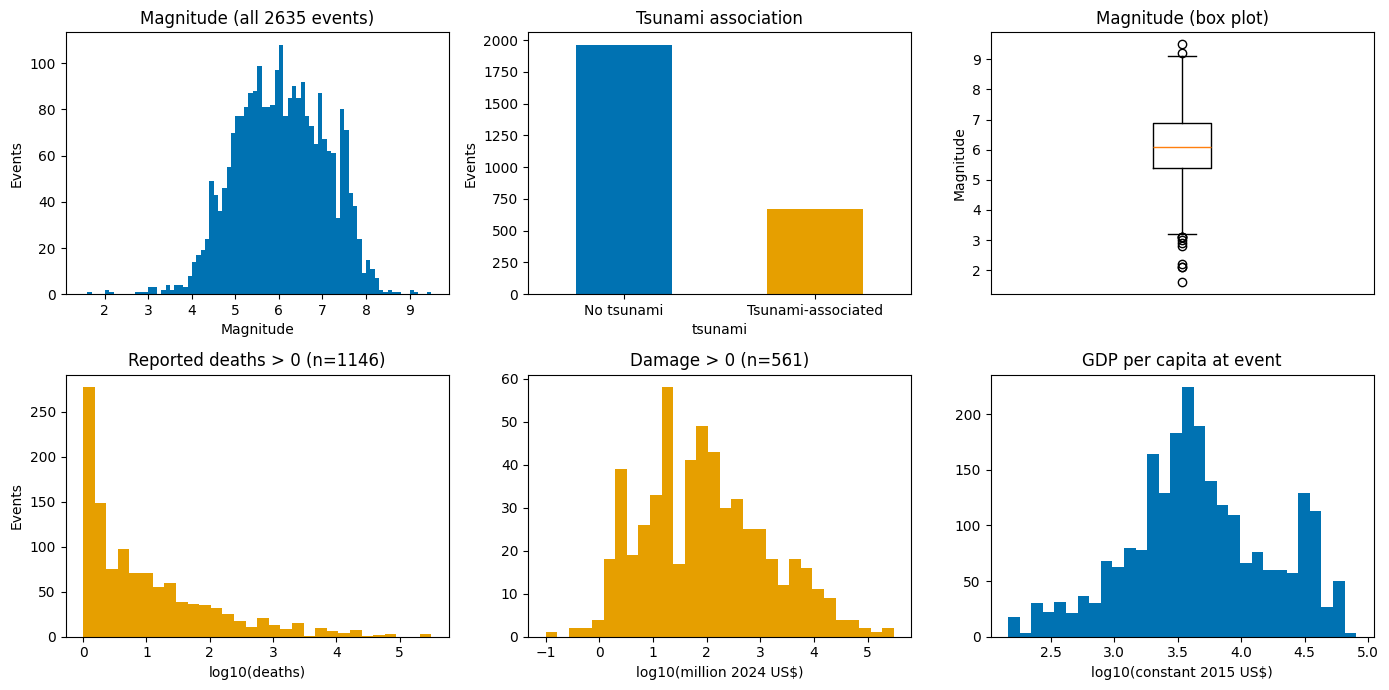

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
ax[0, 0].hist(df["eqMagnitude"].dropna(), bins=np.arange(1.5, 9.6, 0.1), color=BLUE)
ax[0, 0].set(title=f"Magnitude (all {len(df)} events)", xlabel="Magnitude", ylabel="Events")
df["tsunami"].map({0: "No tsunami", 1: "Tsunami-associated"}).value_counts().plot(kind="bar", ax=ax[0, 1], color=[BLUE, ORANGE], rot=0)
ax[0, 1].set(title="Tsunami association", ylabel="Events")
ax[0, 2].boxplot(df["eqMagnitude"].dropna())
ax[0, 2].set(title="Magnitude (box plot)", ylabel="Magnitude", xticks=[])
pos = df.loc[df["deathsTotal"] > 0, "deathsTotal"]
ax[1, 0].hist(np.log10(pos), bins=30, color=ORANGE)
ax[1, 0].set(title=f"Reported deaths > 0 (n={len(pos)})", xlabel="log10(deaths)", ylabel="Events")
dmg = df.loc[df["Total_Damage_2024_USD_Millions"] > 0, "Total_Damage_2024_USD_Millions"]
ax[1, 1].hist(np.log10(dmg), bins=30, color=ORANGE)
ax[1, 1].set(title=f"Damage > 0 (n={len(dmg)})", xlabel="log10(million 2024 US$)")
gdp = df.loc[df["GDP_per_capita_2015USD"] > 0, "GDP_per_capita_2015USD"]
ax[1, 2].hist(np.log10(gdp), bins=30, color=BLUE)
ax[1, 2].set(title="GDP per capita at event", xlabel="log10(constant 2015 US$)")
plt.tight_layout()

### 2.3 Counts of categories

In [16]:
for col in ["tsunami", "mag_band", "death_description", "damage_description"]:
    print(df[col].value_counts(dropna=False).sort_index().to_string(), "\n")

tsunami
0    1964
1     671 

mag_band
<6.0       1166
6.0-6.4     457
6.5-6.9     392
7.0-7.4     310
7.5-7.9     257
8.0+         53 

death_description
1.0     917
2.0      64
3.0     116
4.0      68
NaN    1470 

damage_description
1.0    722
2.0    667
3.0    301
4.0    346
NaN    599 



In [17]:
df["country"].value_counts().head(15)

,count
country,
CHINA,264
INDONESIA,231
IRAN,174
JAPAN,161
USA,128
TURKEY,107
PERU,83
PHILIPPINES,79
RUSSIA,75


In [18]:
# Numbers quoted in the findings
print("Events below M4:", (df["eqMagnitude"] < 4).sum())
print("Median magnitude: no tsunami", df.loc[df["tsunami"] == 0, "eqMagnitude"].median(),
      "| tsunami-associated", df.loc[df["tsunami"] == 1, "eqMagnitude"].median())
df.nlargest(5, "deathsTotal")[["year", "country", "eqMagnitude", "tsunami", "deathsTotal"]]

Events below M4: 32
Median magnitude: no tsunami 5.8 | tsunami-associated 7.0


,year,country,eqMagnitude,tsunami,deathsTotal
1766,2010,HAITI,7.0,1,316000.0
336,1976,CHINA,7.5,0,242769.0
1238,2004,INDONESIA,9.1,1,227899.0
1600,2008,CHINA,7.9,1,87652.0
1412,2005,PAKISTAN,7.6,0,76213.0


### 2.4 Values over time

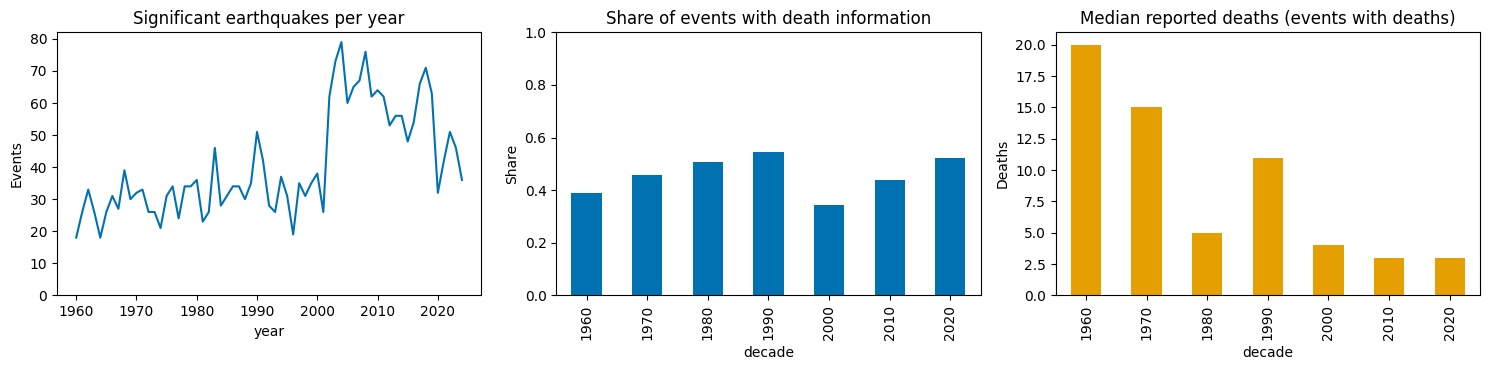

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df.groupby("year").size().plot(ax=ax[0], color=BLUE)
ax[0].set(title="Significant earthquakes per year", ylabel="Events", ylim=(0, None))
known = df.groupby("decade")["Death_Status"].apply(lambda s: (s != "Unknown").mean())
known.plot(kind="bar", ax=ax[1], color=BLUE)
ax[1].set(title="Share of events with death information", ylabel="Share", ylim=(0, 1))
df[df["deathsTotal"] > 0].groupby("decade")["deathsTotal"].median().plot(kind="bar", ax=ax[2], color=ORANGE)
ax[2].set(title="Median reported deaths (events with deaths)", ylabel="Deaths")
plt.tight_layout()

In [20]:
# Per-period table. 2020-2024 is a five-year period, so counts are shown per year.
period = pd.cut(df["year"], [1959, 1969, 1979, 1989, 1999, 2009, 2019, 2024],
                labels=["1960-69", "1970-79", "1980-89", "1990-99", "2000-09", "2010-19", "2020-24"])
years = pd.Series([10, 10, 10, 10, 10, 10, 5], index=period.cat.categories)
pd.DataFrame({
    "events per year": (df.groupby(period, observed=True).size() / years).round(1),
    "share with death information": df.groupby(period, observed=True)["Death_Status"].apply(lambda s: (s != "Unknown").mean()).round(2),
    "median reported deaths (>0)": df[df["deathsTotal"] > 0].groupby(period[df["deathsTotal"] > 0], observed=True)["deathsTotal"].median(),
})

,events per year,share with death information,median reported deaths (>0)
year,,,
1960-69,27.4,0.39,20.0
1970-79,29.5,0.46,15.0
1980-89,32.3,0.51,5.0
1990-99,33.5,0.54,11.0
2000-09,60.8,0.35,4.0
2010-19,59.3,0.44,3.0
2020-24,41.4,0.52,3.0


**Findings (one variable at a time)**
- Magnitude: median 6.1 (middle half 5.4–6.9). Some events below M4 are included in the database because the dataset covers earthquakes meeting different significance criteria, not magnitude alone. The specific inclusion criterion for each event cannot be identified from the available data.
- Reported deaths are extremely skewed: median 5, mean about 1,365, maximum about 316,000 (Haiti 2010). Damage behaves the same way: median about 78 and mean about 3,086 million 2024 US$. We therefore use medians and log scales.
- 671 events (25%) are tsunami-associated.
- The number of recorded events per year is about 27–34 before 2000, about 60 in 2000–2019 and 41 in 2020–24 (a five-year period, shown per year). The median reported toll generally falls (20 in the 1960s, 3 since 2010, with a rise to 11 in the 1990s). Possible reasons include changes in NOAA's coverage, better recording of small events and better disaster reporting; the data do not tell us which, so we do not read this as earthquakes becoming less deadly.
- The share of events with death information stays between 35% and 54% in every decade.

## 3. Relationships
### 3.1 Correlation heatmap (Spearman, robust to skew)

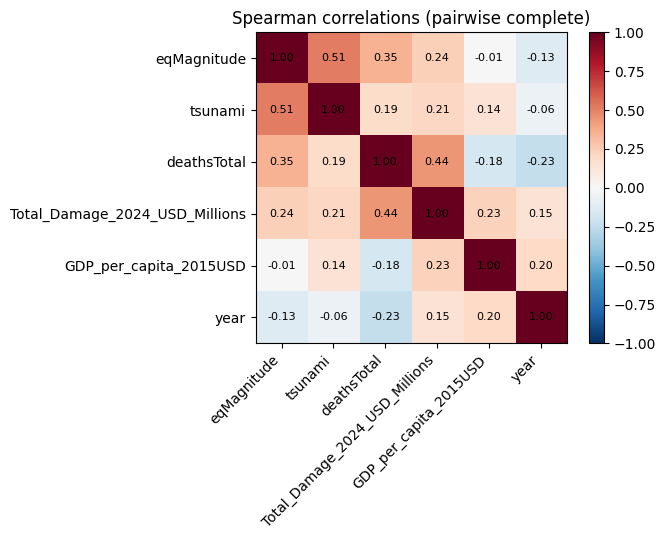

In [21]:
cols = ["eqMagnitude", "tsunami", "deathsTotal", "Total_Damage_2024_USD_Millions",
        "GDP_per_capita_2015USD", "year"]
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Spearman correlations (pairwise complete)")
plt.tight_layout()

### 3.2 RQ1 – Economic prosperity and losses
Only events matched to a World Bank country with GDP for the event year (constant 2015 US$). Unmatched places (Taiwan, territories, ocean regions, Antarctica, ambiguous Congo) stay in the dataset but are left out here.

In [22]:
# GDP analyses: only events with a World Bank country and GDP for that year.
# The other events stay in the dataset and are used in RQ2 and RQ3.
print(df["gdp_missing_reason"].value_counts().to_string())
r1 = df[df["gdp_missing_reason"] == "GDP available"].copy()
print("\nEvents used in RQ1:", len(r1), "of", len(df))

gdp_missing_reason
GDP available                      2378
No World Bank GDP for this year     164
No ISO3 match                        93

Events used in RQ1: 2378 of 2635


In [ ]:

# gdp_quartile (quarters of GDP per capita) was added by add_groups() in scripts/figures.py
summary1 = pd.DataFrame({
    "events": r1.groupby("gdp_quartile", observed=True).size(),
    "median magnitude": r1.groupby("gdp_quartile", observed=True)["eqMagnitude"].median(),
    "share with death information": r1.groupby("gdp_quartile", observed=True)["Death_Status"].apply(lambda s: (s == "Deaths Reported").mean()),
    "median deaths (>0)": r1[r1["deathsTotal"] > 0].groupby("gdp_quartile", observed=True)["deathsTotal"].median(),
    "median damage M 2024$ (>0)": r1[r1["Total_Damage_2024_USD_Millions"] > 0].groupby("gdp_quartile", observed=True)["Total_Damage_2024_USD_Millions"].median(),
})
summary1.round(2)

In [ ]:
# What does each income quarter mean? GDP per capita (constant 2015 US$) of the country in the event year
r1.groupby("gdp_quartile", observed=True)["GDP_per_capita_2015USD"].agg(["count", "min", "median", "max"]).round(0)


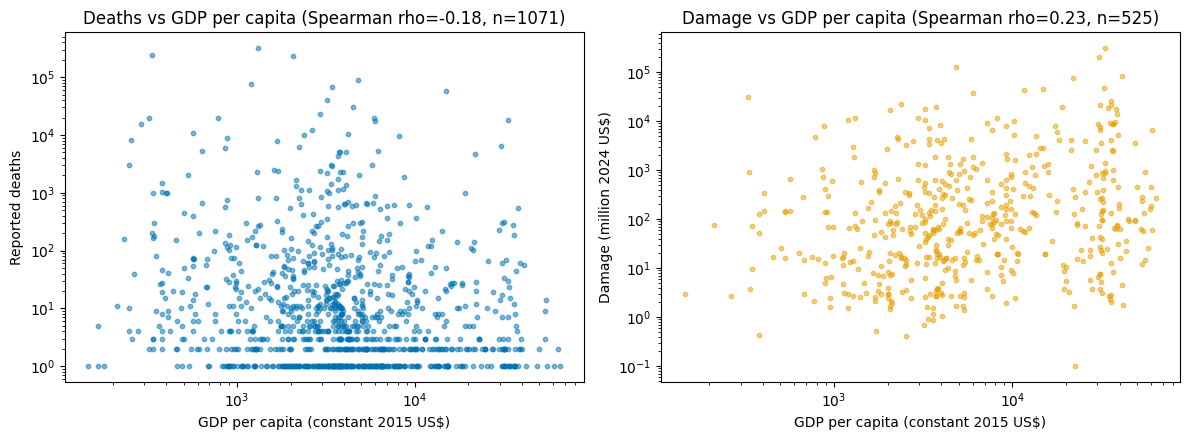

In [24]:
d = r1[r1["deathsTotal"] > 0]
rho = d["GDP_per_capita_2015USD"].corr(d["deathsTotal"], method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(d["GDP_per_capita_2015USD"], d["deathsTotal"], s=10, alpha=0.5, color=BLUE)
ax[0].set(xscale="log", yscale="log", xlabel="GDP per capita (constant 2015 US$)", ylabel="Reported deaths",
          title=f"Deaths vs GDP per capita (Spearman rho={rho:.2f}, n={len(d)})")
g = r1[r1["Total_Damage_2024_USD_Millions"] > 0]
rho2 = g["GDP_per_capita_2015USD"].corr(g["Total_Damage_2024_USD_Millions"], method="spearman")
ax[1].scatter(g["GDP_per_capita_2015USD"], g["Total_Damage_2024_USD_Millions"], s=10, alpha=0.5, color=ORANGE)
ax[1].set(xscale="log", yscale="log", xlabel="GDP per capita (constant 2015 US$)", ylabel="Damage (million 2024 US$)",
          title=f"Damage vs GDP per capita (Spearman rho={rho2:.2f}, n={len(g)})")
plt.tight_layout()

In [25]:
# Reporting completeness by income quarter: information (number or NOAA code) vs a numerical value
q = r1.groupby("gdp_quartile", observed=True)
pd.DataFrame({
    "events": q.size(),
    "death information": q["Death_Status"].apply(lambda s: (s == "Deaths Reported").mean()),
    "numerical death toll": q["deathsTotal"].apply(lambda s: (s > 0).mean()),
    "damage information": q["Economic_Damage_Status"].apply(lambda s: (s == "Damage Reported").mean()),
    "numerical damage": q["Total_Damage_2024_USD_Millions"].apply(lambda s: (s > 0).mean()),
}).round(2)

,events,death information,numerical death toll,damage information,numerical damage
gdp_quartile,,,,,
Q1 (poorest),596,0.51,0.49,0.86,0.19
Q2,593,0.56,0.55,0.80,0.21
Q3,594,0.46,0.46,0.86,0.21
Q4 (richest),595,0.30,0.29,0.69,0.27


In [26]:
# Uncertainty of the correlations
# (a) event-level bootstrap (treats earthquakes as independent)
# (b) country-cluster bootstrap (resamples whole countries; earthquakes in the same country are not independent)
for name, data, col in (("deaths", d, "deathsTotal"), ("damage", g, "Total_Damage_2024_USD_Millions")):
    r, lo, hi = spearman_ci(data["GDP_per_capita_2015USD"], data[col])
    rc, clo, chi, k = spearman_cluster_ci(data, "GDP_per_capita_2015USD", col)
    print(f"GDP vs {name}: rho = {r:.2f}, n = {len(data)} events, {k} countries | "
          f"event bootstrap [{lo:.2f}, {hi:.2f}] | country-cluster bootstrap [{clo:.2f}, {chi:.2f}]")

GDP vs deaths: rho = -0.18, n = 1071 events, 86 countries | event bootstrap [-0.23, -0.11] | country-cluster bootstrap [-0.24, -0.11]
GDP vs damage: rho = 0.23, n = 525 events, 70 countries | event bootstrap [0.15, 0.31] | country-cluster bootstrap [0.07, 0.38]


In [27]:
# Sensitivity 1 - country-weighted: one value per country (countries with at least 3 events with a value),
# so that countries with many events (Japan, USA, China, Indonesia) do not dominate.
gdp_c = r1.groupby("ISO3")["GDP_per_capita_2015USD"].median()
for name, data, col in (("deaths", d, "deathsTotal"), ("damage", g, "Total_Damage_2024_USD_Millions")):
    per_c = data.groupby("ISO3")[col].agg(["median", "size"])
    per_c = per_c[per_c["size"] >= 3].join(gdp_c)
    print(f"Country level, GDP vs median {name}: rho = {per_c['GDP_per_capita_2015USD'].corr(per_c['median'], method='spearman'):.2f}, countries = {len(per_c)}")

# Which countries dominate the poorest and richest quarters?
for qn in ["Q1 (poorest)", "Q4 (richest)"]:
    print(qn, r1.loc[r1["gdp_quartile"] == qn, "country"].value_counts(normalize=True).head(3).round(2).to_dict())

Country level, GDP vs median deaths: rho = -0.35, countries = 48
Country level, GDP vs median damage: rho = 0.28, countries = 33
Q1 (poorest) {'INDONESIA': 0.19, 'CHINA': 0.18, 'INDIA': 0.11}
Q4 (richest) {'JAPAN': 0.25, 'USA': 0.22, 'GREECE': 0.1}


In [28]:
# Sensitivity 2 - without the largest disasters (top 1% of reported deaths)
cut = df["deathsTotal"].quantile(0.99)
d_trim = d[d["deathsTotal"] <= cut]
print(f"GDP vs deaths without the top 1% (> {cut:,.0f} deaths): rho = "
      f"{d_trim['GDP_per_capita_2015USD'].corr(d_trim['deathsTotal'], method='spearman'):.2f}, n = {len(d_trim)}")

GDP vs deaths without the top 1% (> 20,003 deaths): rho = -0.17, n = 1060


### 3.2b Group tests and the figure for the site
The four income quarters are compared with Kruskal-Wallis tests. They work on ranks, so a few very large disasters do not drive the result. Epsilon² is a simple effect size (rough rule of thumb: 0.01 small, 0.06 medium, 0.14 large). The tests are repeated inside three magnitude groups, with Holm-adjusted p-values for the six tests, to check that the result does not only reflect bigger earthquakes in some groups. The tests treat earthquakes as independent (see the country-cluster bootstrap above), so the p-values are exploratory.


In [ ]:
from scipy.stats import kruskal

def kruskal_by_quartile(data, col):
    """Kruskal-Wallis test of `col` across the four income quarters, with epsilon-squared."""
    groups = [data.loc[data["gdp_quartile"] == q, col].dropna() for q in GDP_LABELS]
    groups = [x for x in groups if len(x) > 0]
    h, p = kruskal(*groups)
    n, k = sum(len(x) for x in groups), len(groups)
    return {"H": round(h, 2), "p": p, "epsilon_sq": round(max(0, (h - k + 1) / (n - k)), 3), "n": n}

def holm(p):
    """Holm-adjusted p-values."""
    p = np.asarray(p, dtype=float)
    adj, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

# d and g (events with a numerical toll / damage figure and GDP) come from the scatter cell above
overall = pd.DataFrame([
    {"outcome": "deaths", **kruskal_by_quartile(d, "deathsTotal")},
    {"outcome": "damage", **kruskal_by_quartile(g, "Total_Damage_2024_USD_Millions")},
    {"outcome": "magnitude (check)", **kruskal_by_quartile(r1, "eqMagnitude")},
])
overall["p"] = overall["p"].map(fmt_p)
print("Overall test across the four income quarters")
display(overall)

# Same test inside three magnitude groups
mag3 = pd.cut(r1["eqMagnitude"], [-np.inf, 6.0, 7.0, np.inf], labels=["<6.0", "6.0-6.9", "7.0+"], right=False)
rows = []
for m in mag3.cat.categories:
    for name, data, col in (("deaths", d, "deathsTotal"), ("damage", g, "Total_Damage_2024_USD_Millions")):
        rows.append({"magnitude": m, "outcome": name,
                     **kruskal_by_quartile(data[mag3.loc[data.index] == m], col)})
strat = pd.DataFrame(rows)
strat["p_holm"] = holm(strat["p"])
strat["p"], strat["p_holm"] = strat["p"].map(fmt_p), strat["p_holm"].map(fmt_p)
print("\nInside magnitude groups (Holm-adjusted over the six tests)")
display(strat)


Figure 1 for the site. It comes from `fig1_rq1()` in `scripts/figures.py` and is saved as `visuals/fig1_rq1_income_groups.png`.


In [ ]:
fig = fig1_rq1(df)
plt.show()


**Findings (RQ1)**
- 2,378 events have GDP data. Magnitude is about the same in all four income quarters (median 5.8–6.2), and GDP and magnitude are uncorrelated (Spearman −0.01).
- Human losses tend to be higher in poorer countries: among events with a numerical toll, the median falls from 9 in the poorest quarter to 3 in the richest (rho = −0.18, n = 1,071 events in 86 countries; 95% CI −0.24 to −0.11 with a country-cluster bootstrap). The share of events with death information falls from 51% to 30%.
- Economic losses show the opposite pattern: median damage rises from about 21 to 178 million 2024 US$ (rho = +0.23, n = 525 events in 70 countries). The country-cluster interval is wider than the event-level one (0.07 to 0.38 vs 0.15 to 0.31) because events in the same country are not independent, but it stays above zero.
- Reporting differs by income: a numerical damage figure exists for 27% of events in the richest quarter but 19% in the poorest, while death information is less common in the richest quarter (30% vs 51%). Part of this may come from NOAA's inclusion rule: an earthquake is listed if it meets any one criterion, for example about $1 million of damage, so it can enter the database without deaths ([NOAA NCEI](https://www.ncei.noaa.gov/products/natural-hazards/tsunamis-earthquakes-volcanoes/earthquakes)).
- The pattern is not driven only by the countries with the most events (Japan and the USA make up 47% of the richest quarter): with one value per country, the associations are similar or stronger (deaths rho −0.35, 48 countries; damage rho +0.28, 33 countries). Removing the largest 1% of disasters hardly changes the result (rho −0.17).
- Kruskal-Wallis tests (table 3.2b) agree: deaths and damage both differ between the four income quarters (p < 0.001), but the effects are small (epsilon² = 0.02 for deaths, 0.06 for damage). Inside magnitude groups the damage difference holds in all three (Holm-adjusted p = 0.045 below M6.0, < 0.001 in M6.0–6.9, 0.006 from M7.0). The death difference holds below M6.0 (adjusted p = 0.006) but is not clear in M6.0–6.9 (p = 0.059) or from M7.0 (p = 0.082), where the richest quarter has only 31 events with a toll, so the test has little power there.
- These are associations; building practice, population density and location also differ between countries.

### 3.3 RQ2 – Earthquakes with and without a recorded tsunami association, same magnitude band
Comparable magnitude = same half-unit band. For each loss measure, a magnitude band is compared only when both groups have at least 10 observations with a numerical value. All events are used (GDP not needed). The lowest band (<6.0) is open-ended (it spans M1.6–5.9), so it is not a true half-unit band; results for it are shown but should be read with care.

In [29]:
support = pd.crosstab(df["mag_band"], df["tsunami"]).reindex(MAG_ORDER).fillna(0).astype(int)
support.columns = ["No tsunami", "Tsunami-associated"]
support["both >= 10"] = (support >= 10).all(axis=1)
support

,No tsunami,Tsunami-associated,both >= 10
mag_band,,,
<6.0,1113,53,True
6.0-6.4,371,86,True
6.5-6.9,239,153,True
7.0-7.4,127,183,True
7.5-7.9,109,148,True
8.0+,5,48,False


In [30]:
# 3.3a Reporting completeness: how often are losses reported in each group?
pd.DataFrame({
    "death information": df.groupby("tsunami")["Death_Status"].apply(lambda s: (s == "Deaths Reported").mean()),
    "numerical death toll": df.groupby("tsunami")["deathsTotal"].apply(lambda s: (s > 0).mean()),
    "damage information": df.groupby("tsunami")["Economic_Damage_Status"].apply(lambda s: (s == "Damage Reported").mean()),
    "numerical damage": df.groupby("tsunami")["Total_Damage_2024_USD_Millions"].apply(lambda s: (s > 0).mean()),
}).rename(index={0: "No tsunami", 1: "Tsunami-associated"}).round(3)

,death information,numerical death toll,damage information,numerical damage
tsunami,,,,
No tsunami,0.477,0.469,0.853,0.217
Tsunami-associated,0.341,0.334,0.538,0.200


In [31]:
# Reporting completeness and numbers of events with values, per band and group
bands = support.index[support["both >= 10"]].tolist()
b = df[df["mag_band"].isin(bands)]
out = pd.DataFrame({
    "n events": b.groupby(["mag_band", "tsunami"], observed=True).size(),
    "share with death information": b.groupby(["mag_band", "tsunami"], observed=True)["Death_Status"].apply(lambda s: (s == "Deaths Reported").mean()),
    "median deaths (>0)": b[b["deathsTotal"] > 0].groupby(["mag_band", "tsunami"], observed=True)["deathsTotal"].median(),
    "n deaths": b[b["deathsTotal"] > 0].groupby(["mag_band", "tsunami"], observed=True).size(),
    "median damage M 2024$ (>0)": b[b["Total_Damage_2024_USD_Millions"] > 0].groupby(["mag_band", "tsunami"], observed=True)["Total_Damage_2024_USD_Millions"].median(),
    "n damage": b[b["Total_Damage_2024_USD_Millions"] > 0].groupby(["mag_band", "tsunami"], observed=True).size(),
})
out.round(2)

n events  share with death information  median deaths (>0)  \
mag_band tsunami                                                               
<6.0     0            1113                          0.40                 2.0   
         1              53                          0.13                30.0   
6.0-6.4  0             371                          0.58                 6.0   
         1              86                          0.28                 2.0   
6.5-6.9  0             239                          0.67                11.0   
         1             153                          0.27                22.0   
7.0-7.4  0             127                          0.64                12.5   
         1             183                          0.30                 7.0   
7.5-7.9  0             109                          0.26                40.0   
         1             148                          0.47                15.0   

                  n deaths  median damage M 2024$ (>0)  n damage  
mag_band tsunami                                                  
<6.0     0             443                       43.49       161  
         1               7                     1200.42         5  
6.0-6.4  0             215                       74.79       108  
         1              24                      526.04         7  
6.5-6.9  0             157                       50.57        93  
         1              41                      549.03        24  
7.0-7.4  0              78                      195.42        43  
         1              53                      157.06        28  
7.5-7.9  0              27                      290.63        21  
         1              68                      198.32        45

In [32]:
# 3.3b Reported losses: median with 95% bootstrap interval for every band and group.
# A comparison counts only where BOTH groups have at least 10 events with a value;
# smaller groups are shown but marked as indicative.
rows = []
for col, label in (("deathsTotal", "deaths"), ("Total_Damage_2024_USD_Millions", "damage (M 2024 US$)")):
    for (band, t), grp_ in df[df[col] > 0].groupby(["mag_band", "tsunami"], observed=True):
        m, lo, hi = median_ci(grp_[col])
        rows.append({"loss": label, "band": band, "tsunami": t, "n": len(grp_),
                     "median": round(m, 1), "95% CI": f"[{lo:,.1f}, {hi:,.1f}]"})
ci_table = pd.DataFrame(rows)
ok = ci_table.groupby(["loss", "band"], observed=True)["n"].transform(lambda s: (len(s) == 2) and (s >= 10).all())
ci_table["comparison"] = np.where(ok, "compared", "indicative only (n < 10 or one group missing)")
ci_table

,loss,band,tsunami,n,median,95% CI,comparison
0,deaths,<6.0,0,443,2.0,"[2.0, 3.0]",indicative only (n < 10 or one group missing)
1,deaths,<6.0,1,7,30.0,"[13.0, 71.0]",indicative only (n < 10 or one group missing)
2,deaths,6.0-6.4,0,215,6.0,"[4.0, 8.0]",compared
3,deaths,6.0-6.4,1,24,2.0,"[1.0, 10.0]",compared
4,deaths,6.5-6.9,0,157,11.0,"[6.0, 20.0]",compared
5,deaths,6.5-6.9,1,41,22.0,"[6.0, 31.0]",compared
6,deaths,7.0-7.4,0,78,12.5,"[6.0, 40.0]",compared
7,deaths,7.0-7.4,1,53,7.0,"[4.0, 15.0]",compared
8,deaths,7.5-7.9,0,27,40.0,"[4.0, 103.0]",compared
9,deaths,7.5-7.9,1,68,15.0,"[8.5, 47.5]",compared


In [33]:
# 3.3c Direct comparison: difference of medians (tsunami-associated minus no tsunami)
# with a 95% bootstrap interval, only for bands that pass the n >= 10 rule.
# If the interval contains 0, the data give no clear evidence of a difference.
rows = []
for col, label in (("deathsTotal", "deaths"), ("Total_Damage_2024_USD_Millions", "damage (M 2024 US$)")):
    vals = df[df[col] > 0]
    for band in MAG_ORDER:
        t1 = vals.loc[(vals["mag_band"] == band) & (vals["tsunami"] == 1), col]
        t0 = vals.loc[(vals["mag_band"] == band) & (vals["tsunami"] == 0), col]
        if min(len(t1), len(t0)) < 10:
            continue
        diff, lo, hi = median_diff_ci(t1, t0)
        rows.append({"loss": label, "band": band, "n tsunami": len(t1), "n no tsunami": len(t0),
                     "difference of medians": round(diff, 1), "95% CI": f"[{lo:,.1f}, {hi:,.1f}]",
                     "CI contains 0": lo <= 0 <= hi})
pd.DataFrame(rows)

,loss,band,n tsunami,n no tsunami,difference of medians,95% CI,CI contains 0
0,deaths,6.0-6.4,24,215,-4.0,"[-6.0, 4.5]",True
1,deaths,6.5-6.9,41,157,11.0,"[-7.0, 20.0]",True
2,deaths,7.0-7.4,53,78,-5.5,"[-30.5, 4.0]",True
3,deaths,7.5-7.9,68,27,-25.0,"[-88.0, 24.0]",True
4,damage (M 2024 US$),6.5-6.9,24,93,498.5,"[-23.7, 3,509.0]",True
5,damage (M 2024 US$),7.0-7.4,28,43,-38.4,"[-280.9, 327.8]",True
6,damage (M 2024 US$),7.5-7.9,45,21,-92.3,"[-668.3, 1,077.0]",True


In [34]:
# Sensitivity: are the groups spread differently over time? (reporting improved over the decades)
pd.crosstab(df["decade"], df["tsunami"], normalize="columns").round(3)

tsunami,0,1
decade,,
1960,0.093,0.137
1970,0.103,0.137
1980,0.123,0.122
1990,0.123,0.139
2000,0.258,0.152
2010,0.227,0.219
2020,0.073,0.094


Figure 2 for the site. It comes from `fig2_rq2()` in `scripts/figures.py` and is saved as `visuals/fig2_rq2_tsunami_by_magnitude.png`. It shows the same medians and intervals as table 3.3b, only for bands where both groups have at least 10 events with a value.


In [ ]:
fig = fig2_rq2(df)
plt.show()


**Findings (RQ2)**
We look at two separate things: how often losses are reported (completeness) and how large the reported losses are.

*Reporting completeness*
- Tsunami-associated earthquakes are larger (median M7.0 vs 5.8), so we compare inside magnitude bands.
- Death information is less common for tsunami-associated events (34% vs 48% overall; for example 27% vs 67% in M6.5–6.9). This does **not** show that they are less deadly: generating a tsunami is one of NOAA's inclusion criteria, so offshore events without losses enter the database ([NOAA NCEI](https://www.ncei.noaa.gov/products/natural-hazards/tsunamis-earthquakes-volcanoes/earthquakes)), and a blank can mean zero or unknown.

*Reported losses (events with a numerical value)*
- Deaths can be compared in four bands (M6.0–7.9), where both groups have at least 10 events with a toll. The tsunami group's median is higher in M6.5–6.9 (22 [95% CI 6–31] vs 11 [6–20]) and lower in the other three bands. We also computed the difference of medians (tsunami minus no tsunami) with a 95% bootstrap interval (table 3.3c): in all four bands the interval contains 0 (for example +11 deaths, 95% CI −7 to +20, in M6.5–6.9), so the data give no clear evidence of a difference in either direction.
- Damage can be compared in three bands (M6.5–7.9). The tsunami group's median is higher in M6.5–6.9 (549 vs 51 million), but its interval is very wide (19 to 3,640 million); in M7.0–7.4 and M7.5–7.9 the tsunami group's medians are somewhat lower (157 vs 195 and 198 vs 291 million). In all three bands the 95% interval of the difference of medians contains 0 (for example +499 million, CI −24 to +3,509, in M6.5–6.9). Below M6.5 and in M8.0+ there are fewer than 10 events with a value in one group, so those bands are indicative only.
- The groups are spread similarly over the decades, except that the 2000s hold relatively more non-tsunami events (26% vs 15%).
- A tsunami link does not mean that the tsunami caused the deaths; Haiti 2010 is tsunami-linked although most deaths came from shaking.

### 3.4 RQ3 – Reported deaths and economic damage
Only events with both a reported death toll > 0 and damage > 0 enter the scatter; the description codes give a larger sample.

Events with both values: 438 of 2635


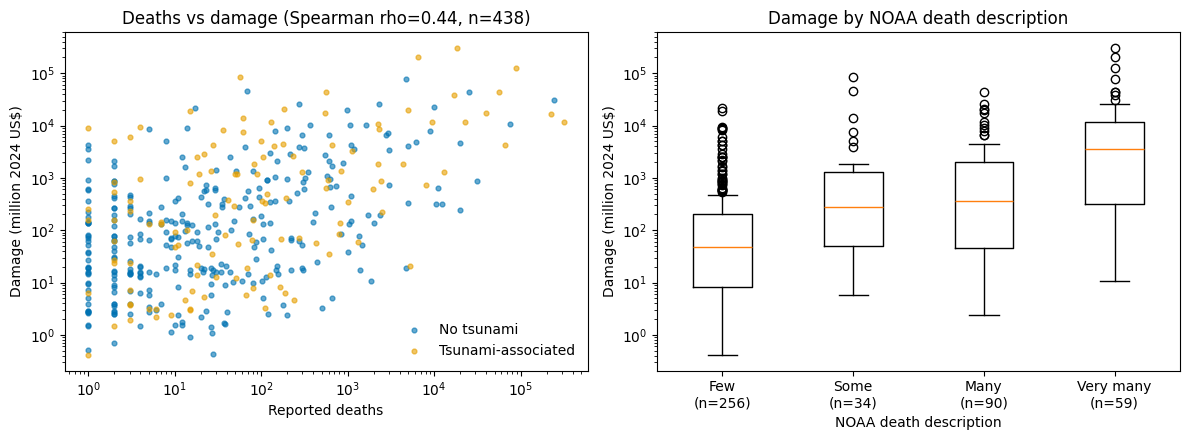

In [35]:
both = df[(df["deathsTotal"] > 0) & (df["Total_Damage_2024_USD_Millions"] > 0)]
rho3 = both["deathsTotal"].corr(both["Total_Damage_2024_USD_Millions"], method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for t, c, lab in ((0, BLUE, "No tsunami"), (1, ORANGE, "Tsunami-associated")):
    p = both[both["tsunami"] == t]
    ax[0].scatter(p["deathsTotal"], p["Total_Damage_2024_USD_Millions"], s=12, alpha=0.6, color=c, label=lab)
ax[0].set(xscale="log", yscale="log", xlabel="Reported deaths", ylabel="Damage (million 2024 US$)",
          title=f"Deaths vs damage (Spearman rho={rho3:.2f}, n={len(both)})")
ax[0].legend(frameon=False)
# Larger sample: damage by NOAA death description (0 None ... 4 Very many)
grp = [df.loc[(df["death_description"] == k) & (df["Total_Damage_2024_USD_Millions"] > 0),
              "Total_Damage_2024_USD_Millions"] for k in range(1, 5)]
ax[1].boxplot(grp)
ax[1].set_xticks(range(1, 5), [f"{l}\n(n={len(g)})" for l, g in zip(["Few", "Some", "Many", "Very many"], grp)])
ax[1].set(yscale="log", xlabel="NOAA death description", ylabel="Damage (million 2024 US$)",
          title="Damage by NOAA death description")
plt.tight_layout()
print("Events with both values:", len(both), "of", len(df))

In [36]:
# Numbers quoted in the RQ3 findings
for t, lab in ((1, "tsunami-associated"), (0, "no tsunami")):
    p = both[both["tsunami"] == t]
    print(f"Spearman rho, {lab}: {p['deathsTotal'].corr(p['Total_Damage_2024_USD_Millions'], method='spearman'):.2f} (n={len(p)})")
pd.Series({l: g.median() for l, g in zip(["Few", "Some", "Many", "Very many"], grp)},
          name="median damage, million 2024 US$").round(1)

Spearman rho, tsunami-associated: 0.48 (n=123)
Spearman rho, no tsunami: 0.40 (n=315)


,"median damage, million 2024 US$"
Few,48.2
Some,283.2
Many,361.5
Very many,3497.7


In [37]:
# Uncertainty, magnitude control and sensitivity for RQ3
r, lo, hi = spearman_ci(both["deathsTotal"], both["Total_Damage_2024_USD_Millions"])
print(f"Analysis 1 (numerical deaths vs damage): rho = {r:.2f} [95% CI {lo:.2f}, {hi:.2f}], n = {len(both)}")
print(f"Analysis 2 (NOAA death category vs damage): n = {sum(len(x) for x in grp)}")

# Within the same magnitude band: is the link only a size effect?
bb = both.assign(band=pd.cut(both["eqMagnitude"], [0, 6, 6.5, 7, 7.5, 10], right=False,
                             labels=["<6.0", "6.0-6.4", "6.5-6.9", "7.0-7.4", "7.5+"]))
print(bb.groupby("band", observed=True).apply(
    lambda x: pd.Series({"n": len(x), "rho": round(x["deathsTotal"].corr(x["Total_Damage_2024_USD_Millions"], method="spearman"), 2)})).to_string())

# Without the largest 1% of deaths and of damage
trim = both[(both["deathsTotal"] <= df["deathsTotal"].quantile(0.99)) &
            (both["Total_Damage_2024_USD_Millions"] <= df["Total_Damage_2024_USD_Millions"].quantile(0.99))]
print(f"Without the top 1%: rho = {trim['deathsTotal'].corr(trim['Total_Damage_2024_USD_Millions'], method='spearman'):.2f}, n = {len(trim)}")

# Are the 438 events with both values different from the rest?
df.assign(has_both=(df["deathsTotal"] > 0) & (df["Total_Damage_2024_USD_Millions"] > 0)).groupby("has_both").agg(
    events=("id", "size"), median_magnitude=("eqMagnitude", "median"), median_year=("year", "median"),
    tsunami_share=("tsunami", "mean"), median_gdp=("GDP_per_capita_2015USD", "median")).round(2)

Analysis 1 (numerical deaths vs damage): rho = 0.44 [95% CI 0.36, 0.51], n = 438
Analysis 2 (NOAA death category vs damage): n = 439
             n   rho
band                
<6.0     105.0  0.18
6.0-6.4   91.0  0.40
6.5-6.9   96.0  0.36
7.0-7.4   60.0  0.50
7.5+      86.0  0.65
Without the top 1%: rho = 0.39, n = 421


/tmp/ipykernel_635/3099675917.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(bb.groupby("band", observed=True).apply(


,events,median_magnitude,median_year,tsunami_share,median_gdp
has_both,,,,,
False,2197,6.0,2003.0,0.25,4367.95
True,438,6.6,1995.0,0.28,4024.91


**Findings (RQ3)**
- Two analyses with different samples. Analysis 1 uses the 438 events (17%) with both a numerical toll and a damage figure. Analysis 2 uses the 439 events with a NOAA death category and a damage figure. The categories (Few, Some, Many, Very many) are ranges, not counts, so the two analyses are not the same measurement.
- Analysis 1: reported deaths and damage show a moderate positive association (Spearman rho = 0.44, 95% CI 0.36 to 0.51). It is similar for tsunami-associated events (0.48) and other events (0.40).
- This is not only a size effect: inside each magnitude band the association remains positive, and it is generally stronger for larger earthquakes (rho 0.18 below M6.0, 0.40 in M6.0–6.4, 0.65 in M7.5+). Removing the largest 1% of disasters barely changes it (rho 0.39).
- Analysis 2: median damage rises from about 48 million 2024 US$ for "Few" deaths to about 283 ("Some"), 362 ("Many") and 3,498 ("Very many").
- The 438 events are somewhat larger (median M6.6 vs 6.0) and older (median year 1995 vs 2003) than the rest, so results may not hold for all significant earthquakes.

## 4. Summary and next steps
- Loss data are incomplete, and NOAA does not separate "no deaths" from "unknown". All loss results describe events with reported values, and reporting itself differs by income and by tsunami association.
- RQ1: earthquakes of similar size are associated with higher reported death tolls in poorer countries and higher absolute damage in richer countries (weak associations that hold at country level and with a country-cluster bootstrap).
- RQ2: tsunami-associated events have death information less often. Among events with reported losses, the difference of medians within each magnitude band has a 95% interval that contains 0 for both deaths and damage: no clear difference.
- RQ3: higher reported death tolls go with higher damage (rho = 0.44), also within magnitude bands.
- M2 figures: `scripts/figures.py` → `visuals/fig1_rq1_income_groups.png` (RQ1) and `visuals/fig2_rq2_tsunami_by_magnitude.png` (RQ2).
- Next (M3): damage relative to national GDP (needs total GDP, `NY.GDP.MKTP.CD`), a trend figure using events per year, and RQ3 as a figure.